In [ ]:

# Import Necessary Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

from scipy.sparse import csr_matrix, hstack

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC, SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, roc_auc_score
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

#Load the Dataset
DATA_PATH = "spam.csv"

try:
    df = pd.read_csv(DATA_PATH, encoding="latin-1")
except UnicodeDecodeError:
    df = pd.read_csv(DATA_PATH, encoding="utf-8")

# Support the standard Kaggle CSV and the UCI tab-separated text file
if {"v1", "v2"}.issubset(df.columns):
    df = df[["v1", "v2"]].rename(
        columns={"v1": "label", "v2": "message"}
    )
elif {"label", "message"}.issubset(df.columns):
    df = df[["label", "message"]]
else:
    raise ValueError(
        "Expected Kaggle columns v1/v2 or label/message. "
        "For the UCI SMSSpamCollection file, use "
        "pd.read_csv(DATA_PATH, sep='\\t', header=None, "
        "names=['label','message'], encoding='utf-8') instead."
    )

df = df.dropna(subset=["label", "message"]).copy()
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()
df = df[df["label"].isin(["ham", "spam"])]
df = df[df["message"].str.len() > 0]
df = df.drop_duplicates(subset=["label", "message"]).reset_index(drop=True)

df["target"] = df["label"].map({"ham": 0, "spam": 1})

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())
display(df.head())


Dataset loaded successfully!
Shape: (5158, 3)

Class distribution:
label
ham     4516
spam     642
Name: count, dtype: int64


,label,message,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


Missing values:
 label      0
message    0
dtype: int64

Duplicate rows: 0

Class percentages:
label
ham     87.55
spam    12.45
Name: proportion, dtype: float64


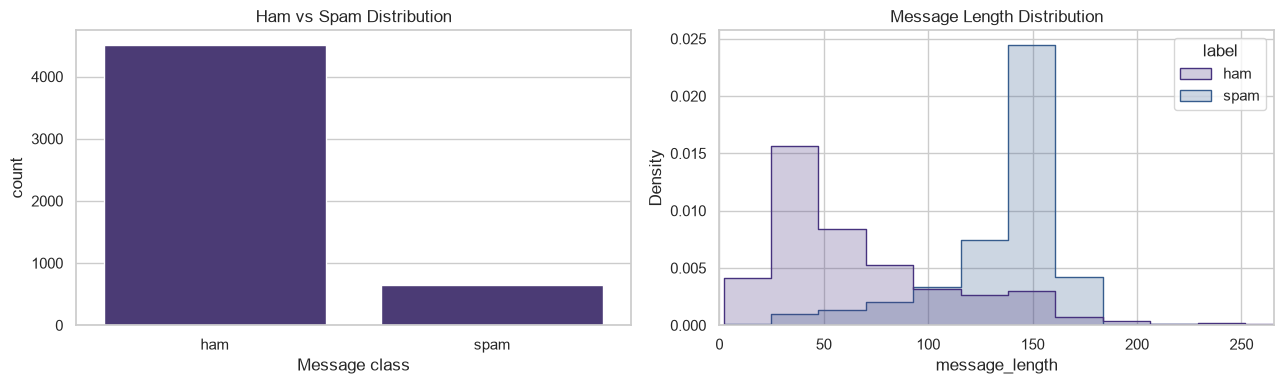

In [ ]:

# Exploratory Data Analysis
print("Missing values:\n", df[["label", "message"]].isnull().sum())
print("\nDuplicate rows:", df.duplicated(subset=["label", "message"]).sum())
print("\nClass percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(data=df, x="label", ax=axes[0])
axes[0].set_title("Ham vs Spam Distribution")
axes[0].set_xlabel("Message class")

df["message_length"] = df["message"].str.len()
sns.histplot(
    data=df, x="message_length", hue="label",
    bins=40, element="step", stat="density",
    common_norm=False, ax=axes[1]
)
axes[1].set_title("Message Length Distribution")
axes[1].set_xlim(0, df["message_length"].quantile(0.99))

plt.tight_layout()
plt.show()


In [ ]:

# Feature Engineering
df["message_length"] = df["message"].str.len()
df["digit_count"] = df["message"].apply(
    lambda x: sum(ch.isdigit() for ch in x)
)
df["capital_count"] = df["message"].apply(
    lambda x: sum(ch.isupper() for ch in x)
)

print("Engineered features:")
display(
    df[["message", "message_length", "digit_count",
        "capital_count", "label"]].head(10)
)

print("\nAverage features by class:")
display(
    df.groupby("label")[
        ["message_length", "digit_count", "capital_count"]
    ].mean().round(2)
)


Engineered features:


,message,message_length,digit_count,capital_count,label
0,"Go until jurong point, crazy.. Available only ...",111,0,3,ham
1,Ok lar... Joking wif u oni...,29,0,2,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,155,25,10,spam
3,U dun say so early hor... U c already then say...,49,0,2,ham
4,"Nah I don't think he goes to usf, he lives aro...",61,0,2,ham
5,FreeMsg Hey there darling it's been 3 week's n...,148,4,7,spam
6,Even my brother is not like to speak with me. ...,77,0,2,ham
7,As per your request 'Melle Melle (Oru Minnamin...,160,1,10,ham
8,WINNER!! As a valued network customer you have...,158,19,12,spam
9,Had your mobile 11 months or more? U R entitle...,154,13,14,spam



Average features by class:


,message_length,digit_count,capital_count
label,,,
ham,70.42,0.29,3.90
spam,137.59,15.40,15.13


In [ ]:

#Splitting
X_text = df["message"]
y = df["target"].astype(int)

X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X_text, y, test_size=0.40,
    stratify=y, random_state=RANDOM_STATE
)

X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp, test_size=0.50,
    stratify=y_temp, random_state=RANDOM_STATE
)

print(f"Training:   {len(X_train_text):,} ({len(X_train_text)/len(df):.1%})")
print(f"Validation: {len(X_val_text):,} ({len(X_val_text)/len(df):.1%})")
print(f"Testing:    {len(X_test_text):,} ({len(X_test_text)/len(df):.1%})")
print("\nSpam rates:")
print("Train:", round(y_train.mean(), 4))
print("Val:  ", round(y_val.mean(), 4))
print("Test: ", round(y_test.mean(), 4))


Training:   3,094 (60.0%)
Validation: 1,032 (20.0%)
Testing:    1,032 (20.0%)

Spam rates:
Train: 0.1244
Val:   0.125
Test:  0.124


In [ ]:

#TF-IDF Vectorizer
tfidf = TfidfVectorizer(max_features=1000, dtype=np.float64)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf = tfidf.transform(X_val_text)
X_test_tfidf = tfidf.transform(X_test_text)

print("TF-IDF vocabulary size:", len(tfidf.vocabulary_))
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)

print("\nSample vocabulary:", list(tfidf.get_feature_names_out()[:20]))


TF-IDF vocabulary size: 1000
Training TF-IDF shape: (3094, 1000)
Validation TF-IDF shape: (1032, 1000)
Test TF-IDF shape: (1032, 1000)

Sample vocabulary: ['000', '03', '04', '0800', '08000839402', '08000930705', '10', '100', '1000', '10p', '11', '12', '12hrs', '150', '150p', '150ppm', '16', '18', '1st', '200']


In [ ]:

#Scale Numeric Features
feature_cols = ["message_length", "digit_count", "capital_count"]

def numeric_features(text_series):
    return np.array([
        [
            len(msg),
            sum(ch.isdigit() for ch in msg),
            sum(ch.isupper() for ch in msg)
        ]
        for msg in text_series
    ], dtype=float)

N_train = numeric_features(X_train_text)
N_val = numeric_features(X_val_text)
N_test = numeric_features(X_test_text)

scaler = StandardScaler()
N_train_scaled = scaler.fit_transform(N_train)
N_val_scaled = scaler.transform(N_val)
N_test_scaled = scaler.transform(N_test)

# Sparse matrices allow efficient combination with TF-IDF
X_train = hstack([X_train_tfidf, csr_matrix(N_train_scaled)], format="csr")
X_val = hstack([X_val_tfidf, csr_matrix(N_val_scaled)], format="csr")
X_test = hstack([X_test_tfidf, csr_matrix(N_test_scaled)], format="csr")

print("Combined feature shape:", X_train.shape)
print("Features = 1000 TF-IDF maximum + 3 numeric features")


Combined feature shape: (3094, 1003)
Features = 1000 TF-IDF maximum + 3 numeric features


In [9]:

C_values = [0.01, 0.1, 1, 10, 100]
linear_results = []

for C in C_values:
    model = LinearSVC(C=C, random_state=RANDOM_STATE, max_iter=10000)
    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    pred = model.predict(X_val)
    linear_results.append({
        "C": C,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "Train Time (s)": elapsed
    })

linear_results = pd.DataFrame(linear_results)
display(linear_results.round(4))

best_C = float(
    linear_results.sort_values(
        ["F1", "Recall"], ascending=False
    ).iloc[0]["C"]
)
print("Best Linear SVM C:", best_C)


,C,Accuracy,Precision,Recall,F1,Train Time (s)
0,0.01,0.9651,0.9429,0.7674,0.8462,0.0111
1,0.10,0.9758,0.9483,0.8527,0.8980,0.0141
2,1.00,0.9835,0.9590,0.9070,0.9323,0.0097
3,10.00,0.9806,0.9360,0.9070,0.9213,0.0298
4,100.00,0.9797,0.9286,0.9070,0.9176,0.0222


Best Linear SVM C: 1.0


Best Linear SVM validation report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       903
        Spam       0.96      0.91      0.93       129

    accuracy                           0.98      1032
   macro avg       0.97      0.95      0.96      1032
weighted avg       0.98      0.98      0.98      1032



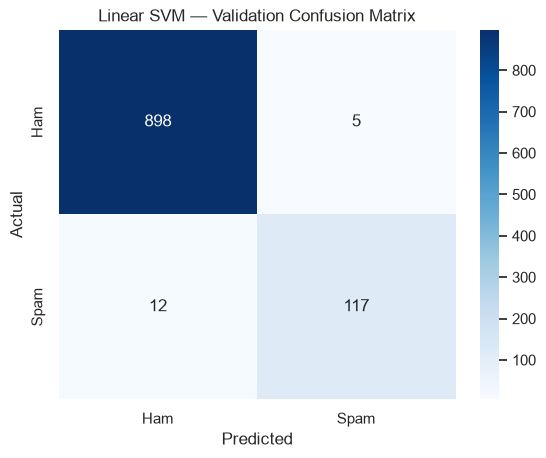

In [10]:

linear_model = LinearSVC(
    C=best_C, random_state=RANDOM_STATE, max_iter=10000
)

start = time.perf_counter()
linear_model.fit(X_train, y_train)
linear_train_time = time.perf_counter() - start

linear_val_pred = linear_model.predict(X_val)

print("Best Linear SVM validation report:")
print(classification_report(
    y_val, linear_val_pred,
    labels=[0, 1], target_names=["Ham", "Spam"], zero_division=0
))

cm = confusion_matrix(y_val, linear_val_pred, labels=[0, 1])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)
plt.title("Linear SVM — Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [ ]:

#Analyze false Positive and negatives
val_errors = pd.DataFrame({
    "message": X_val_text.reset_index(drop=True),
    "actual": y_val.reset_index(drop=True),
    "predicted": linear_val_pred
})

val_errors["actual_label"] = val_errors["actual"].map({0: "Ham", 1: "Spam"})
val_errors["predicted_label"] = val_errors["predicted"].map({0: "Ham", 1: "Spam"})

fp = val_errors[
    (val_errors["actual"] == 0) & (val_errors["predicted"] == 1)
]
fn = val_errors[
    (val_errors["actual"] == 1) & (val_errors["predicted"] == 0)
]

print("FALSE POSITIVES — legitimate messages marked spam")
display(fp[["message", "actual_label", "predicted_label"]].head(5))

print("FALSE NEGATIVES — spam messages missed")
display(fn[["message", "actual_label", "predicted_label"]].head(5))

print("Error counts | FP:", len(fp), "| FN:", len(fn))


FALSE POSITIVES — legitimate messages marked spam


,message,actual_label,predicted_label
296,Hey...Great deal...Farm tour 9am to 5pm $95/pa...,Ham,Spam
523,This is ur face test ( 1 2 3 4 5 6 7 8 9 &lt;...,Ham,Spam
718,Solve d Case : A Man Was Found Murdered On &l...,Ham,Spam
731,My tuition is at 330. Hm we go for the 1120 to...,Ham,Spam
812,Ee msg na poortiyagi odalebeku: Hanumanji 7 na...,Ham,Spam


FALSE NEGATIVES — spam messages missed


,message,actual_label,predicted_label
38,dating:i have had two of these. Only started a...,Spam,Ham
101,Cashbin.co.uk (Get lots of cash this weekend!)...,Spam,Ham
196,Sorry! U can not unsubscribe yet. THE MOB offe...,Spam,Ham
368,"Latest News! Police station toilet stolen, cop...",Spam,Ham
478,In The Simpsons Movie released in July 2007 na...,Spam,Ham


Error counts | FP: 5 | FN: 12


In [ ]:

# RBF SVM Grid SearchCV
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1]
}

rbf_grid = GridSearchCV(
    estimator=SVC(kernel="rbf", class_weight=None),
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1,
    refit=True,
    return_train_score=True
)

start = time.perf_counter()
rbf_grid.fit(X_train, y_train)
rbf_search_time = time.perf_counter() - start

print("Best RBF parameters:", rbf_grid.best_params_)
print("Best mean CV F1:", round(rbf_grid.best_score_, 4))
print("Grid search time (seconds):", round(rbf_search_time, 2))


Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best RBF parameters: {'C': 10, 'gamma': 0.1}
Best mean CV F1: 0.9445
Grid search time (seconds): 25.55


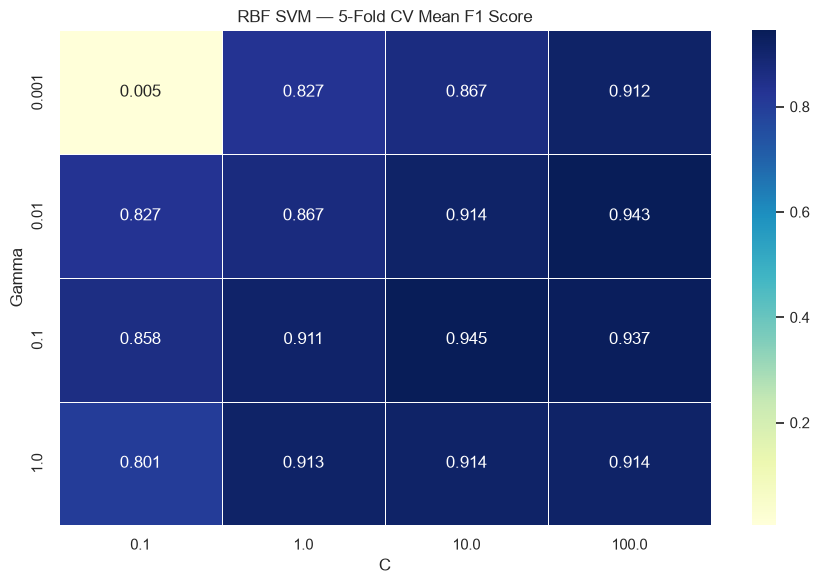

,param_C,param_gamma,mean_test_score,std_test_score,mean_train_score,rank_test_score
10,10.0,0.100,0.9445,0.0239,0.9918,1
13,100.0,0.010,0.9432,0.0215,0.9882,2
14,100.0,0.100,0.9371,0.0276,0.9990,3
9,10.0,0.010,0.9142,0.0295,0.9277,4
11,10.0,1.000,0.9136,0.0230,1.0000,5
15,100.0,1.000,0.9136,0.0230,1.0000,5
7,1.0,1.000,0.9133,0.0263,0.9825,7
12,100.0,0.001,0.9115,0.0321,0.9251,8
6,1.0,0.100,0.9112,0.0327,0.9215,9
5,1.0,0.010,0.8675,0.0447,0.8713,10


In [ ]:

# Visualizing
cv_results = pd.DataFrame(rbf_grid.cv_results_)

heatmap_data = cv_results.pivot(
    index="param_gamma",
    columns="param_C",
    values="mean_test_score"
).astype(float)

heatmap_data.index = heatmap_data.index.astype(float)
heatmap_data.columns = heatmap_data.columns.astype(float)

plt.figure(figsize=(9, 6))
sns.heatmap(
    heatmap_data, annot=True, fmt=".3f",
    cmap="YlGnBu", linewidths=0.5
)
plt.title("RBF SVM — 5-Fold CV Mean F1 Score")
plt.xlabel("C")
plt.ylabel("Gamma")
plt.tight_layout()
plt.show()

display(
    cv_results[[
        "param_C", "param_gamma",
        "mean_test_score", "std_test_score",
        "mean_train_score", "rank_test_score"
    ]].sort_values("rank_test_score").head(10).round(4)
)


RBF SVM validation report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       903
        Spam       0.98      0.93      0.95       129

    accuracy                           0.99      1032
   macro avg       0.98      0.96      0.97      1032
weighted avg       0.99      0.99      0.99      1032



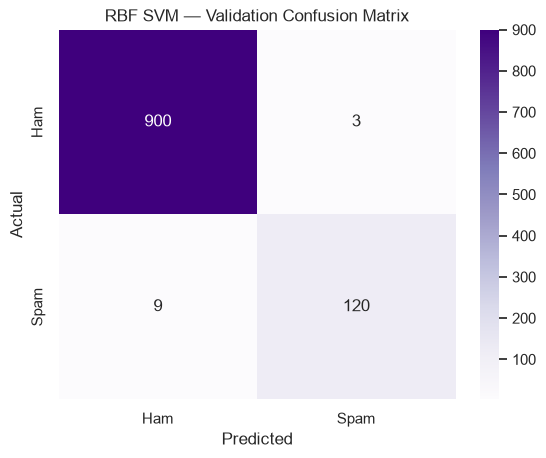

In [14]:

rbf_model = rbf_grid.best_estimator_
rbf_val_pred = rbf_model.predict(X_val)

print("RBF SVM validation report:")
print(classification_report(
    y_val, rbf_val_pred,
    labels=[0, 1], target_names=["Ham", "Spam"], zero_division=0
))

cm = confusion_matrix(y_val, rbf_val_pred, labels=[0, 1])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Purples",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)
plt.title("RBF SVM — Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [15]:

models = {
    "Linear SVM": linear_model,
    "RBF SVM": rbf_model
}

test_predictions = {}
test_scores = {}
comparison_rows = []

for name, model in models.items():
    start = time.perf_counter()
    pred = model.predict(X_test)
    inference_time = time.perf_counter() - start

    # LinearSVC and SVC both provide decision_function scores.
    scores = model.decision_function(X_test)

    test_predictions[name] = pred
    test_scores[name] = scores

    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "Inference Time (s)": inference_time
    })

comparison = pd.DataFrame(comparison_rows).set_index("Model")
print("FINAL HELD-OUT TEST RESULTS")
display(comparison.round(4))

for name, pred in test_predictions.items():
    print(f"\n{name} — Test classification report")
    print(classification_report(
        y_test, pred,
        labels=[0, 1], target_names=["Ham", "Spam"], zero_division=0
    ))


FINAL HELD-OUT TEST RESULTS


,Accuracy,Precision,Recall,F1,ROC-AUC,Inference Time (s)
Model,,,,,,
Linear SVM,0.9913,0.9837,0.9453,0.9641,0.9901,0.0012
RBF SVM,0.9913,0.9837,0.9453,0.9641,0.9866,0.1033



Linear SVM — Test classification report
              precision    recall  f1-score   support

         Ham       0.99      1.00      1.00       904
        Spam       0.98      0.95      0.96       128

    accuracy                           0.99      1032
   macro avg       0.99      0.97      0.98      1032
weighted avg       0.99      0.99      0.99      1032


RBF SVM — Test classification report
              precision    recall  f1-score   support

         Ham       0.99      1.00      1.00       904
        Spam       0.98      0.95      0.96       128

    accuracy                           0.99      1032
   macro avg       0.99      0.97      0.98      1032
weighted avg       0.99      0.99      0.99      1032



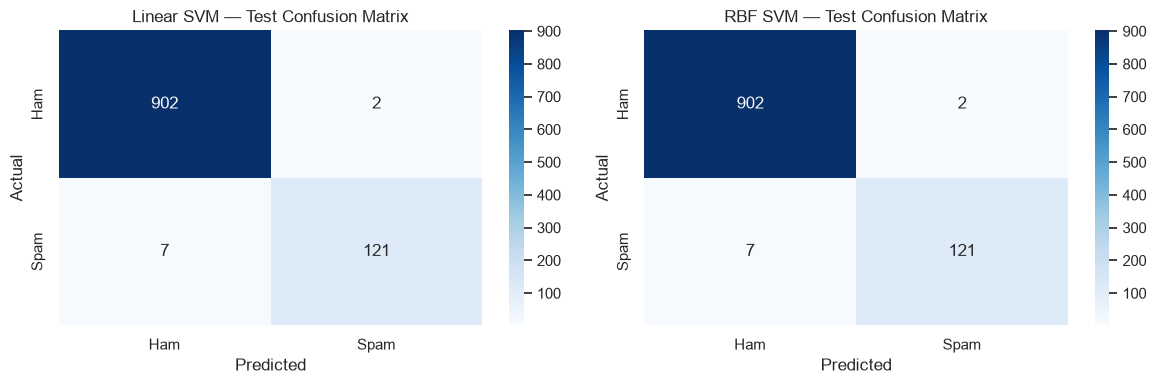

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, pred) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"],
        ax=ax
    )
    ax.set_title(f"{name} — Test Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


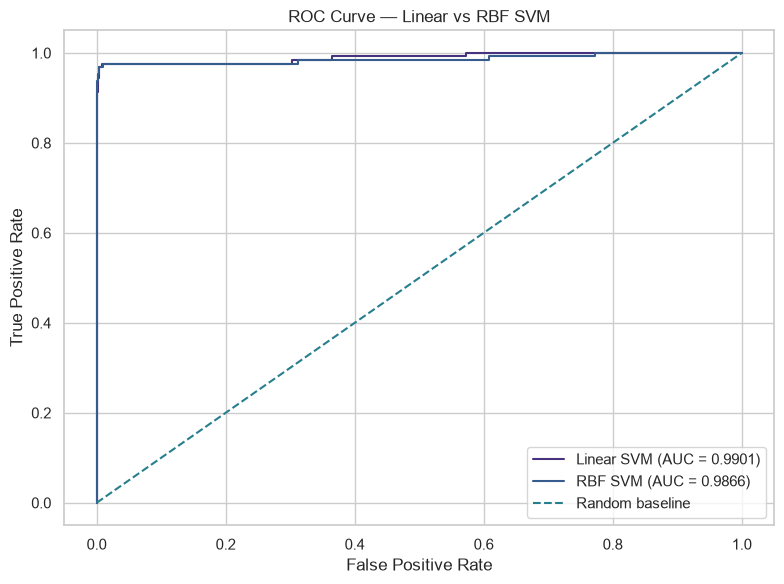

In [17]:

plt.figure(figsize=(8, 6))

for name, scores in test_scores.items():
    fpr, tpr, thresholds = roc_curve(y_test, scores)
    auc_value = roc_auc_score(y_test, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Linear vs RBF SVM")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


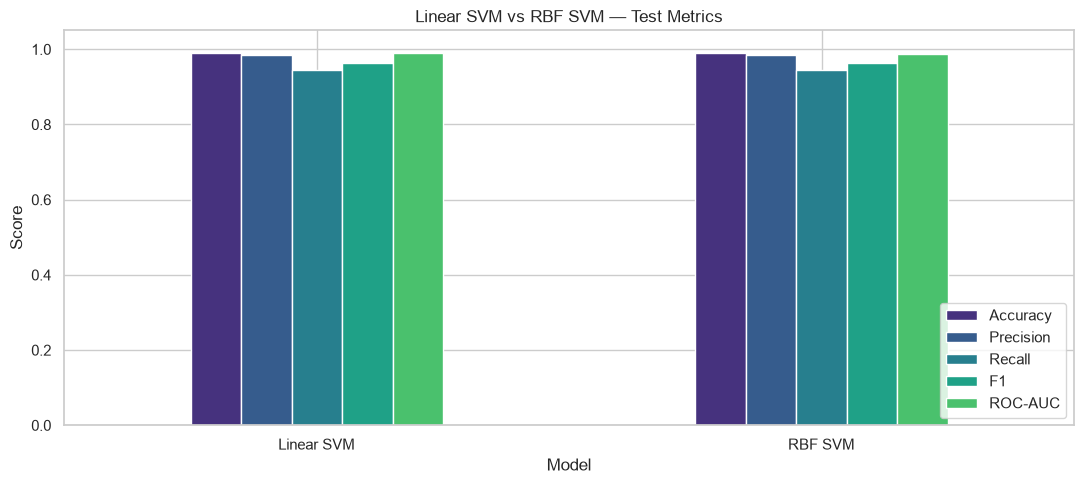

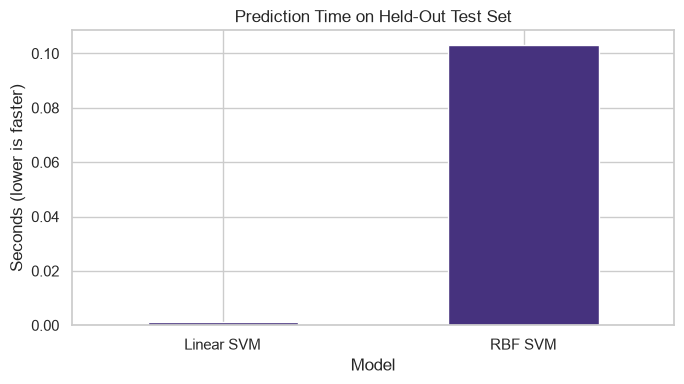

In [18]:

comparison[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1.05)
)
plt.title("Linear SVM vs RBF SVM — Test Metrics")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

comparison["Inference Time (s)"].plot(
    kind="bar", figsize=(7, 4)
)
plt.title("Prediction Time on Held-Out Test Set")
plt.ylabel("Seconds (lower is faster)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [19]:

print("=" * 65)
print("FINAL PROJECT SUMMARY")
print("=" * 65)

for name, row in comparison.iterrows():
    print(f"\n{name}")
    print(f"  Accuracy : {row['Accuracy']:.4f}")
    print(f"  Precision: {row['Precision']:.4f}")
    print(f"  Recall   : {row['Recall']:.4f}")
    print(f"  F1 Score : {row['F1']:.4f}")
    print(f"  ROC-AUC  : {row['ROC-AUC']:.4f}")
    print(f"  Test prediction time: {row['Inference Time (s)']:.4f}s")

# Compare F1 first; speed and simplicity are tie-breakers.
if comparison.loc["Linear SVM", "F1"] >= comparison.loc["RBF SVM", "F1"] - 0.01:
    recommended = "Linear SVM"
    reason = (
        "Comparable F1 with a generally faster prediction path "
        "and easier interpretation of linear feature weights."
    )
else:
    recommended = "RBF SVM"
    reason = (
        "Its test F1 is meaningfully higher; benchmark latency and "
        "memory before deploying it."
    )

print("\nPROVISIONAL PRODUCTION RECOMMENDATION:", recommended)
print(reason)
print("\nDecision notes:")
print("- Prioritize spam recall to reduce missed spam.")
print("- Monitor precision to avoid blocking legitimate messages.")
print("- Validate on newer, real-world messages before production.")
print("- Measure latency and memory on the intended deployment hardware.")
print("- Recheck performance as spam patterns change.")
print("\nAssignment completed successfully!")


FINAL PROJECT SUMMARY

Linear SVM
  Accuracy : 0.9913
  Precision: 0.9837
  Recall   : 0.9453
  F1 Score : 0.9641
  ROC-AUC  : 0.9901
  Test prediction time: 0.0012s

RBF SVM
  Accuracy : 0.9913
  Precision: 0.9837
  Recall   : 0.9453
  F1 Score : 0.9641
  ROC-AUC  : 0.9866
  Test prediction time: 0.1033s

PROVISIONAL PRODUCTION RECOMMENDATION: Linear SVM
Comparable F1 with a generally faster prediction path and easier interpretation of linear feature weights.

Decision notes:
- Prioritize spam recall to reduce missed spam.
- Monitor precision to avoid blocking legitimate messages.
- Validate on newer, real-world messages before production.
- Measure latency and memory on the intended deployment hardware.
- Recheck performance as spam patterns change.

Assignment completed successfully!
